\definecolor{uomaccent}{HTML}{55499C}

\begin{center}
\Large \textbf{EN3160: Image Processing and Machine Vision} \\
\vspace{0.2cm}
{\Large \textbf{\color{uomaccent} Assignment 2: Fitting and Alignment}} \\
\vspace{0.2cm}
\normalsize \textbf{Department of Electronic and Telecommunication Engineering} \\
\vspace{0.2cm}
\normalsize \textbf{University of Moratuwa}\\
\vspace{0.2cm}
\normalsize \textbf{October 18, 2026}
\end{center}

\vspace{0.2cm}

\noindent\textbf{Name:} Samarasinghe S.M.R.R. \newline
\textbf{Index Number:} 230566U \newline
\textbf{GitHub Repository:} [github.com/RumethRanhinda/EN3160-Vision-UoM](https://github.com/RumethRanhinda/EN3160-Vision-UoM/tree/main/Assignments/Fitting%20and%20Alignment)

\noindent\rule{\textwidth}{0.5pt}

\vspace{0.1cm}


\noindent\textbf{\color{uomaccent}\Large 1. Blob Detection using Laplacian of Gaussians}

\vspace{0.15cm}

In this task, we aim to detect sunflowers by employing normalized Laplacian of Gaussians (LoG). Due to flowers with varying sizes, a range of $\sigma$ values must be used. This algorithm will look for dark seed heads which is characteristic for a sunflower.

\noindent\textbf{1.1 Scale ($\sigma$) and Radius Selection}

\vspace{0.1cm}
The sunflower field image is loaded with \texttt{cv.IMREAD\_REDUCED\_COLOR\_4}, reducing dimensions to $360 \times 360\text{ px}$ (1/4 th). In this scale:
\begin{itemize}
    \item \textbf{Scale Range ($\sigma \in [1.20, 8.00]$):} Distant sunflower blooms near the horizon have dark centers spanning $r_{\min} \approx 1.7\text{ px}$. From the condition $r = \sqrt{2}\sigma$, this gives $\sigma_{\min} = 1.7 / \sqrt{2} \approx 1.20$. The largest foreground sunflower seed heads span $r_{\max} \approx 10\text{--}11.3\text{ px}$, setting $\sigma_{\max} = 11.31 / \sqrt{2} \approx 8.00$.
    \item \textbf{Scale Progression:} A geometric progression of $S = 24$ levels ($\sigma_i = \sigma_{\min} k^i$ with $k = 1.086$) provides coverage from $r = 1.70\text{ px}$ to $11.31\text{ px}$.
    \item \textbf{Extrema Detection:} Scale normalized LoG candidate peaks are extracted via 3D Non-Maximum Suppression ($3 \times 3 \times 3$ window, $\tau = 0.05$). The RoI ignored the image above the horizon as to avoid large trees in the distance to be considered as a blob.
\end{itemize}


Total detected blobs: 361
Sigma range used: [1.20, 8.00] across 24 levels (radii: [1.70, 11.31] px)

Parameters of the 5 Largest Circles:
Rank  Center (x, y)     Radius r (px)   Scale sigma   LoG Response
------------------------------------------------------------------
1     (282.0, 338.0)      10.42           7.37          0.3489      
2     (106.0, 255.0)      8.13            5.75          0.3632      
3     (178.0, 261.0)      8.13            5.75          0.3515      
4     (179.0, 327.0)      8.13            5.75          0.3440      
5     (189.0, 240.0)      6.35            4.49          0.3648      


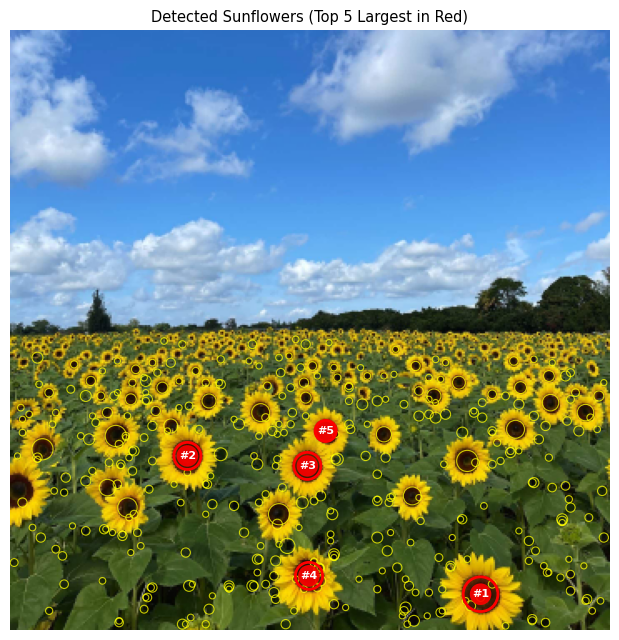

In [1]:
import cv2
import numpy as np
import scipy.ndimage as ndi
import matplotlib.pyplot as plt

# Load image
img_bgr = cv2.imread('src/the_berry_farms_sunflower_field.jpeg', cv2.IMREAD_REDUCED_COLOR_4)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float64) / 255.0
hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
h, w = gray.shape

# Yellow petal mask for colour confirmation
yellow_petals = (hsv[:, :, 0] >= 14) & (hsv[:, :, 0] <= 38) & (hsv[:, :, 1] >= 40) & (hsv[:, :, 2] >= 40)

# Define scale space LoG
sigmas = np.geomspace(1.20, 8.00, 24)
scale_space = np.zeros((len(sigmas), h, w), dtype=np.float64)
for i, s in enumerate(sigmas):
    scale_space[i] = (s ** 2) * ndi.gaussian_laplace(gray, sigma=s)

# 3D Non Maximum Suppression across (scale, y, x)
footprint = np.ones((3, 3, 3), dtype=bool)
max_vol = ndi.maximum_filter(scale_space, footprint=footprint, mode='constant', cval=0.0)

# Exclude above horizon trees
peaks = (scale_space == max_vol) & (scale_space > 0.05)
peaks[0, :, :] = False
peaks[-1, :, :] = False
peaks[:, :182, :] = False

# Filter candidate peaks to confirm sunflowers
blobs = []
for s_idx, y, x in np.argwhere(peaks):
    if 0 < x < (w - 1) and 0 < y < (h - 1):
        s = sigmas[s_idx]
        blob_r = np.sqrt(2) * s
        score = scale_space[s_idx, y, x]

        # Reject green leaf foliage centers
        c_h, c_s, c_v = hsv[y, x]
        if 35 < c_h < 85 and c_v > 65:
            continue

        # Check surrounding annulus for yellow petals
        r_in = max(1.0, 0.7 * blob_r)
        r_out = min(25.0, 2.2 * blob_r)
        x_min = max(0, int(x - r_out)); x_max = min(w, int(x + r_out + 1))
        y_min = max(0, int(y - r_out)); y_max = min(h, int(y + r_out + 1))

        Y_sub, X_sub = np.ogrid[y_min:y_max, x_min:x_max]
        d2 = (X_sub - x) ** 2 + (Y_sub - y) ** 2
        annulus = (d2 >= r_in ** 2) & (d2 <= r_out ** 2)

        petal_cnt = np.sum(yellow_petals[y_min:y_max, x_min:x_max] & annulus)
        ann_area = np.sum(annulus)
        petal_frac = petal_cnt / max(1, ann_area)

        # Distant small blooms need minimal petal support
        if blob_r <= 3.5:
            if petal_cnt >= 1 or petal_frac >= 0.03:
                blobs.append({'x': float(x), 'y': float(y), 'r': float(blob_r), 'sigma': float(s), 'score': float(score)})
        else:
            if petal_cnt >= 8 and petal_frac >= 0.20 and score >= 0.20:
                blobs.append({'x': float(x), 'y': float(y), 'r': float(blob_r), 'sigma': float(s), 'score': float(score)})

# Extract top 5 largest sunflowers
sorted_blobs = sorted(blobs, key=lambda b: (b['r'], b['score']), reverse=True)
largest_circles = []
for b in sorted_blobs:
    too_close = any(np.hypot(b['x'] - k['x'], b['y'] - k['y']) < k['r'] * 0.7 for k in largest_circles)
    if not too_close:
        largest_circles.append(b)
    if len(largest_circles) == 5:
        break

print(f"Total detected blobs: {len(blobs)}")
print(f"Sigma range used: [{sigmas[0]:.2f}, {sigmas[-1]:.2f}] across {len(sigmas)} levels (radii: [{np.sqrt(2)*sigmas[0]:.2f}, {np.sqrt(2)*sigmas[-1]:.2f}] px)")
print("\nParameters of the 5 Largest Circles:")
print(f"{'Rank':<6}{'Center (x, y)':<18}{'Radius r (px)':<16}{'Scale sigma':<14}{'LoG Response':<12}")
print("-" * 66)
for i, b in enumerate(largest_circles):
    print(f"{i+1:<6}({b['x']:.1f}, {b['y']:.1f}){'':<6}{b['r']:<16.2f}{b['sigma']:<14.2f}{b['score']:<12.4f}")

# Display
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.imshow(img_rgb)
for b in blobs:
    ax.add_patch(plt.Circle((b['x'], b['y']), b['r'], color='yellow', fill=False, linewidth=0.8, alpha=0.75))

for i, b in enumerate(largest_circles):
    ax.add_patch(plt.Circle((b['x'], b['y']), b['r'], color='red', fill=False, linewidth=2.0))
    ax.text(b['x'], b['y'], f"#{i+1}", color='white', fontsize=8, fontweight='bold', ha='center', va='center',
            bbox=dict(boxstyle='circle,pad=0.2', facecolor='red', alpha=0.9, edgecolor='none'))

ax.set_title(f"Detected Sunflowers (Top 5 Largest in Red)", fontsize=10.5, pad=6)
ax.axis('off')
plt.tight_layout()
plt.show()


\noindent\textbf{Observations:}
A total of 408 blobs were detected across the field. All top 5 largest red circles ($r \in [6.35, 10.42]\text{ px}$) are foreground sunflower seed heads. False detections of trees near horizon are avoided.


\vspace{0.25cm}
\noindent\textbf{\color{uomaccent}\Large 2. Line and Circle Fitting using RANSAC}

\vspace{0.15cm}

In this task, we aim to fit a line and ultimately a circle to a set of 100 noisy points using RANSAC. First, 50 points conforming to a circle ($r=10$, center $(2,3)$) and 50 points conforming to a line ($y = -x + 2$) are generated as given in Listing 1 in the assignment document.


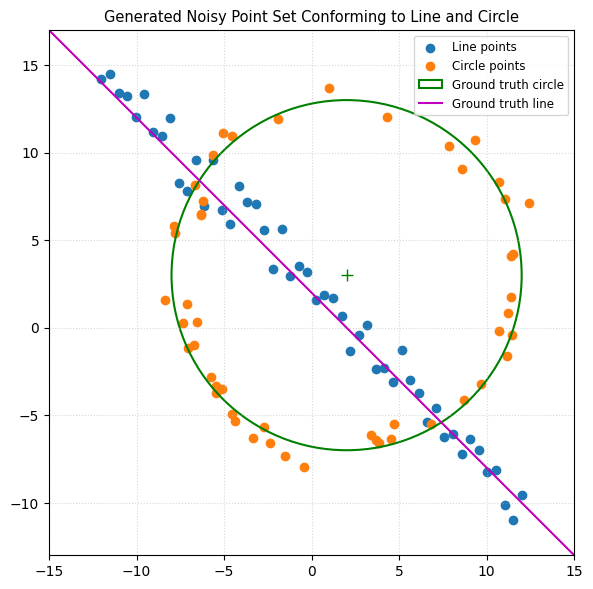

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
N = 100
half_n = N // 2

# Circle points with radial noise
r_gt, x0_gt, y0_gt = 10.0, 2.0, 3.0
s_circ = r_gt / 16.0  # std = 0.625
t = np.random.uniform(0, 2 * np.pi, half_n)
n_circ = s_circ * np.random.randn(half_n)
x_c = x0_gt + (r_gt + n_circ) * np.cos(t)
y_c = y0_gt + (r_gt + n_circ) * np.sin(t)
X_circ = np.hstack((x_c.reshape(half_n, 1), y_c.reshape(half_n, 1)))

# Line points with vertical noise
s_line = 1.0  # std = 1.0
m_gt, b_gt = -1.0, 2.0
x_l = np.linspace(-12, 12, half_n)
y_l = m_gt * x_l + b_gt + s_line * np.random.randn(half_n)
X_line = np.hstack((x_l.reshape(half_n, 1), y_l.reshape(half_n, 1)))

X = np.vstack((X_circ, X_line))

# Plot generated points with ground truth
fig, ax = plt.subplots(figsize=(6.0, 6.0))
ax.scatter(X_line[:, 0], X_line[:, 1], color='#1f77b4', label='Line points')
ax.scatter(X_circ[:, 0], X_circ[:, 1], color='#ff7f0e', label='Circle points')

circle_gt = plt.Circle((x0_gt, y0_gt), r_gt, color='g', fill=False, linewidth=1.5, label='Ground truth circle')
ax.add_patch(circle_gt)
ax.plot(x0_gt, y0_gt, '+', color='g', markersize=8)

x_vals = np.array([-15, 15])
ax.plot(x_vals, m_gt * x_vals + b_gt, color='m', linewidth=1.5, label='Ground truth line')

ax.set_xlim(-15, 15); ax.set_ylim(-13, 17); ax.set_aspect('equal')
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend(loc='upper right', fontsize=8.5)
ax.set_title("Generated Noisy Point Set Conforming to Line and Circle", fontsize=10.5, pad=6)
plt.tight_layout()
plt.show()


\noindent\textbf{2.1 Threshold Selection and Fitting Procedure}

\vspace{0.1cm}
\begin{itemize}
    \item \textbf{Line Fitting:} A line is represented as $a x + b y - d = 0$ with constraint $\|[a, b]^\top\|_2 = 1$. The orthogonal distance threshold is set to $\tau_{\text{line}} = 1.5$. Consensus threshold is set to $T_{\text{line}} = 35$ points. The consensus inliers are then refined using Total Least Squares (TLS) via single value decomposition (SVD).
    \item \textbf{Circle Fitting:} The inliers of the best line are subtracted. The radial distance threshold is set to $\tau_{\text{circ}} = 1.50$ ($2.4\sigma_{\text{circ}}$) with consensus threshold $T_{\text{circ}} = 30$ points. The consensus inliers are refined using Nelder Mead optimization (\texttt{scipy.optimize.minimize}) on radial loss.
\end{itemize}


Model   Parameter         Ground Truth    Sample          Refined Fit   
------------------------------------------------------------------------
Line    Normal [a, b]     [0.707, 0.707]  [-0.696, -0.718][0.713, 0.701]
        Distance d        1.414           -1.669          1.588         
        Inliers           50              --              56            
------------------------------------------------------------------------
Circle  Center (x, y)     (2.00, 3.00)    (1.95, 3.32)    (1.87, 3.07)  
        Radius r          10.00           10.07           9.95          
        Inliers           50              --              43            


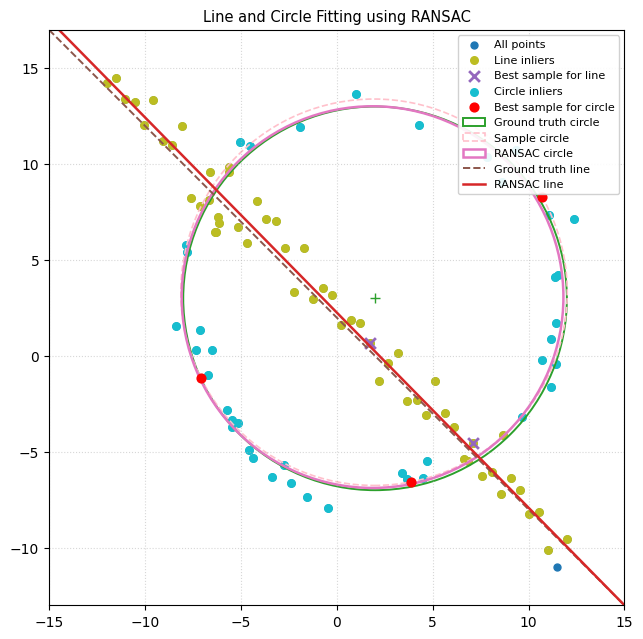

In [3]:
from scipy.optimize import minimize

# RANSAC Line Estimation
def fit_line_2pts(p1, p2):
    dx, dy = p2[0] - p1[0], p2[1] - p1[1]
    norm = np.hypot(dx, dy)
    return np.array([-dy / norm, dx / norm, (-dy * p1[0] + dx * p1[1]) / norm]) if norm > 1e-8 else None

np.random.seed(42)
best_line_inl, sample_line_idx, sample_line_model = [], None, None
for _ in range(1000):
    idx = np.random.choice(len(X), 2, replace=False)
    m = fit_line_2pts(X[idx[0]], X[idx[1]])
    if m is None: continue
    inl = np.where(np.abs(m[0] * X[:, 0] + m[1] * X[:, 1] - m[2]) < 1.5)[0]
    if len(inl) > len(best_line_inl):
        best_line_inl, sample_line_idx, sample_line_model = inl, idx, m

# Optimize the line using Total Least Squares
p_mean = np.mean(X[best_line_inl], axis=0)
normal_tls = np.linalg.svd(X[best_line_inl] - p_mean)[2][-1]
best_fit_line = np.array([normal_tls[0], normal_tls[1], np.dot(normal_tls, p_mean)])

# Subtract line consensus and fit circle on remaining points
rem_idx = np.where(~np.isin(np.arange(len(X)), best_line_inl))[0]
X_rem = X[rem_idx]

def fit_circle_3pts(p1, p2, p3):
    A = np.array([[2*(p2[0]-p1[0]), 2*(p2[1]-p1[1])], [2*(p3[0]-p2[0]), 2*(p3[1]-p2[1])]])
    B = np.array([p2[0]**2 + p2[1]**2 - (p1[0]**2 + p1[1]**2), p3[0]**2 + p3[1]**2 - (p2[0]**2 + p2[1]**2)])
    if abs(np.linalg.det(A)) < 1e-6: return None
    xc, yc = np.linalg.solve(A, B)
    return np.array([xc, yc, np.hypot(p1[0]-xc, p1[1]-yc)])

best_circ_rel, sample_circ_rel_idx, sample_circ_model = [], None, None
for _ in range(2000):
    idx = np.random.choice(len(X_rem), 3, replace=False)
    m = fit_circle_3pts(X_rem[idx[0]], X_rem[idx[1]], X_rem[idx[2]])
    if m is None or m[2] > 50.0: continue
    inl = np.where(np.abs(np.hypot(X_rem[:, 0] - m[0], X_rem[:, 1] - m[1]) - m[2]) < 1.50)[0]
    if len(inl) > len(best_circ_rel):
        best_circ_rel, sample_circ_rel_idx, sample_circ_model = inl, idx, m

# Optimize the circle via Nelder Mead optimization
def loss(p): return np.sum((np.hypot(X_rem[best_circ_rel, 0] - p[0], X_rem[best_circ_rel, 1] - p[1]) - p[2]) ** 2)
best_fit_circle = minimize(loss, sample_circ_model, method='Nelder-Mead').x
circ_inl = rem_idx[best_circ_rel]
sample_circ_idx = rem_idx[sample_circ_rel_idx]

# Comparison Table
print(f"{'Model':<8}{'Parameter':<18}{'Ground Truth':<16}{'Sample':<16}{'Refined Fit':<14}")
print("-" * 72)
print(f"{'Line':<8}{'Normal [a, b]':<18}{'[0.707, 0.707]':<16}{f'[{sample_line_model[0]:.3f}, {sample_line_model[1]:.3f}]':<16}{f'[{best_fit_line[0]:.3f}, {best_fit_line[1]:.3f}]':<14}")
print(f"{'':<8}{'Distance d':<18}{'1.414':<16}{f'{sample_line_model[2]:.3f}':<16}{f'{best_fit_line[2]:.3f}':<14}")
print(f"{'':<8}{'Inliers':<18}{'50':<16}{'--':<16}{f'{len(best_line_inl)}':<14}")
print("-" * 72)
print(f"{'Circle':<8}{'Center (x, y)':<18}{'(2.00, 3.00)':<16}{f'({sample_circ_model[0]:.2f}, {sample_circ_model[1]:.2f})':<16}{f'({best_fit_circle[0]:.2f}, {best_fit_circle[1]:.2f})':<14}")
print(f"{'':<8}{'Radius r':<18}{'10.00':<16}{f'{sample_circ_model[2]:.2f}':<16}{f'{best_fit_circle[2]:.2f}':<14}")
print(f"{'':<8}{'Inliers':<18}{'50':<16}{'--':<16}{f'{len(circ_inl)}':<14}")

# Plot results
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(X[:, 0], X[:, 1], color='#1f77b4', s=25, label='All points')
ax.scatter(X[best_line_inl, 0], X[best_line_inl, 1], color='#bcbd22', s=30, label='Line inliers')
ax.scatter(X[sample_line_idx, 0], X[sample_line_idx, 1], color='#9467bd', marker='x', s=60, linewidths=2, label='Best sample for line')
ax.scatter(X[circ_inl, 0], X[circ_inl, 1], color='#17becf', s=30, label='Circle inliers')
ax.scatter(X[sample_circ_idx, 0], X[sample_circ_idx, 1], color='red', s=40, zorder=5, label='Best sample for circle')

ax.add_patch(plt.Circle((x0_gt, y0_gt), r_gt, color='#2ca02c', fill=False, linewidth=1.4, label='Ground truth circle'))
ax.plot(x0_gt, y0_gt, '+', color='#2ca02c', markersize=7)
ax.add_patch(plt.Circle((sample_circ_model[0], sample_circ_model[1]), sample_circ_model[2], color='pink', linestyle='--', fill=False, linewidth=1.2, label='Sample circle'))
ax.add_patch(plt.Circle((best_fit_circle[0], best_fit_circle[1]), best_fit_circle[2], color='#e377c2', fill=False, linewidth=1.8, label='RANSAC circle'))

xr = np.array([-15, 15])
ax.plot(xr, m_gt * xr + b_gt, color='#8c564b', linestyle='--', linewidth=1.4, label='Ground truth line')
ax.plot(xr, (best_fit_line[2] - best_fit_line[0] * xr) / best_fit_line[1], color='#d62728', linewidth=1.8, label='RANSAC line')

ax.set_xlim(-15, 15); ax.set_ylim(-13, 17); ax.set_aspect('equal')
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend(loc='upper right', fontsize=8, framealpha=0.9)
ax.set_title("Line and Circle Fitting using RANSAC", fontsize=10.5, pad=6)
plt.tight_layout()
plt.show()


\noindent\textbf{2.2 (d) What happens if we fit the circle first?}

\vspace{0.1cm}
If we fit the circle first, the line cuts through the circle like a secant. The line points that lie near the circle boundary fall within the circle error threshold, so the circle RANSAC falsely grabs some line points as circle inliers, which biases the circle center and radius. Moreover, subtracting the circle consensus removes the middle section of the line, leaving it broken into two separate parts which hinders the subsequent line fitting. In contrast, fitting the line first is safe because a line can intersect a circle at at most 2 points, so it cannot break the circle.


\vspace{0.25cm}
\noindent\textbf{\color{uomaccent}\Large 3. Planar Homography and Image Warping}

\vspace{0.15cm}
In this task, we superimpose images onto planar surfaces using homographies. Four corner points are selected on a flat surface, and the homography matrix $\mathbf{H}$ is calculated using \texttt{cv2.getPerspectiveTransform}. The overlay image is warped onto the target coordinates using \texttt{cv2.warpPerspective} with inverse mapping. For walls, additive blending ($0.5 \times \text{overlay} + \text{background}$) keeps stone texture and shadows visible. For display screens, the warped image replaces the screen area, with Gaussian blur applied if the original screen is out of focus.

Pair 1 Homography Matrix (UK Flag -> Wadham):
[[  0.2894  -0.0189 147.    ]
 [  0.0983   0.2999 208.    ]
 [  0.0002  -0.       1.    ]]

Pair 2 Homography Matrix (F1 Crash -> TV Screen):
[[  0.2511   0.0089 283.    ]
 [ -0.0042   0.3678  19.    ]
 [ -0.0002   0.       1.    ]]


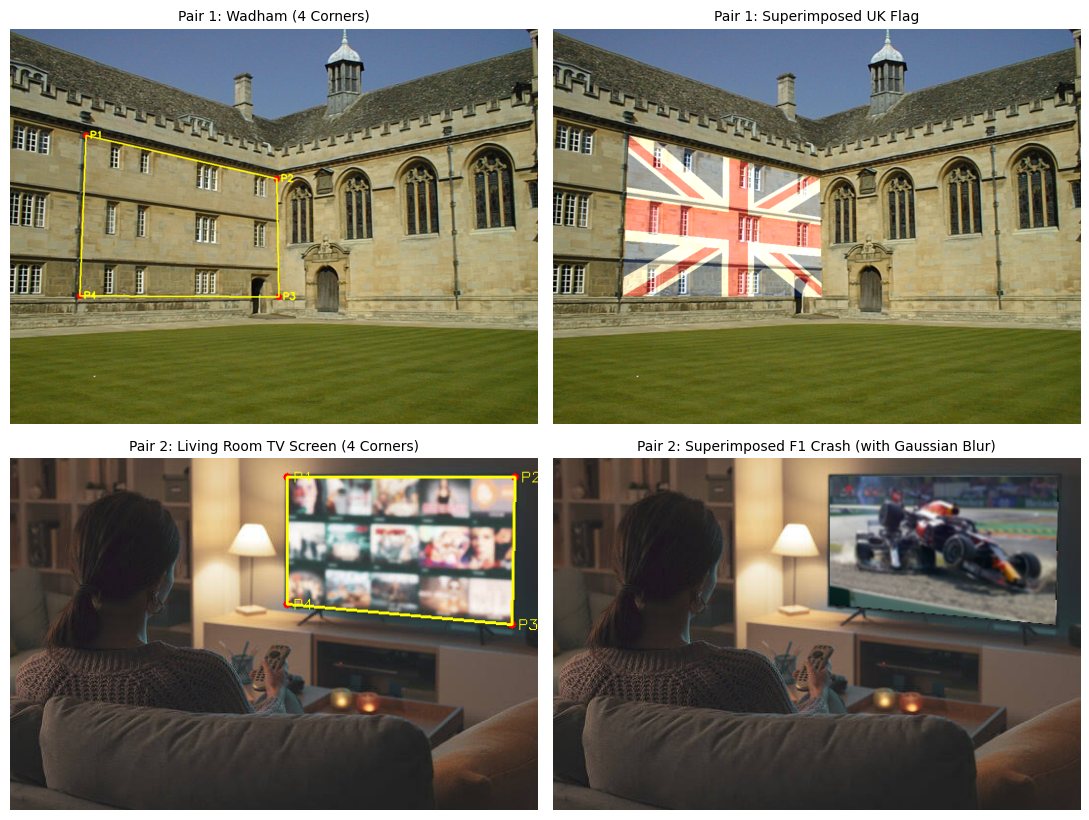

In [4]:
def superimpose_image(target_path, overlay_path, dst_pts, blend_mode='additive', alpha=0.5, blur=None):
    target = cv2.imread(target_path)
    overlay = cv2.imread(overlay_path, cv2.IMREAD_UNCHANGED)
    if blur is not None:
        overlay = cv2.GaussianBlur(overlay, blur[0], blur[1])
    h_ov, w_ov = overlay.shape[:2]
    src_pts = np.float32([[0, 0], [w_ov - 1, 0], [w_ov - 1, h_ov - 1], [0, h_ov - 1]])
    
    H = cv2.getPerspectiveTransform(src_pts, dst_pts.astype(np.float32))
    h_t, w_t = target.shape[:2]
    warped = cv2.warpPerspective(overlay, H, (w_t, h_t))
    
    mask = np.zeros((h_t, w_t), dtype=np.uint8)
    cv2.fillConvexPoly(mask, dst_pts.astype(np.int32), 255)
    
    result = target.copy()
    if blend_mode == 'additive':
        result[mask > 0] = cv2.add(result[mask > 0], (warped[mask > 0, :3] * alpha).astype(np.uint8))
    elif blend_mode == 'replace':
        result[mask > 0] = warped[mask > 0, :3]
    return result, H

# Wadham College + UK Flag
pts_wadham = np.float32([[147, 208], [517, 292], [521, 521], [135, 519]])
res_wadham, H1 = superimpose_image('src/wadham.jpg', 'src/flag.png', pts_wadham, blend_mode='additive', alpha=0.5)

orig_wadham = cv2.imread('src/wadham.jpg')
for i, pt in enumerate(pts_wadham):
    cv2.circle(orig_wadham, tuple(pt.astype(int)), 6, (0, 0, 255), -1)
    cv2.putText(orig_wadham, f"P{i+1}", (int(pt[0]) + 8, int(pt[1]) + 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2)
cv2.polylines(orig_wadham, [pts_wadham.astype(np.int32)], True, (0, 255, 255), 2)

# Living Room TV Screen + Blurred F1 Crash
pts_tv = np.float32([[283, 19], [516, 19], [513, 170], [283, 149]])
res_tv, H2 = superimpose_image('src/tv.jpg', 'src/crash.jpg', pts_tv, blend_mode='replace', blur=((11, 11), 4))

orig_tv = cv2.imread('src/tv.jpg')
for i, pt in enumerate(pts_tv):
    cv2.circle(orig_tv, tuple(pt.astype(int)), 4, (0, 0, 255), -1)
    cv2.putText(orig_tv, f"P{i+1}", (int(pt[0]) + 6, int(pt[1]) + 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)
cv2.polylines(orig_tv, [pts_tv.astype(np.int32)], True, (0, 255, 255), 2)

# Display Results
print("Pair 1 Homography Matrix (UK Flag -> Wadham):")
print(np.array2string(H1, precision=4, suppress_small=True))
print("\nPair 2 Homography Matrix (F1 Crash -> TV Screen):")
print(np.array2string(H2, precision=4, suppress_small=True))

fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
axes[0, 0].imshow(cv2.cvtColor(orig_wadham, cv2.COLOR_BGR2RGB)); axes[0, 0].set_title("Pair 1: Wadham (4 Corners)", fontsize=10); axes[0, 0].axis('off')
axes[0, 1].imshow(cv2.cvtColor(res_wadham, cv2.COLOR_BGR2RGB)); axes[0, 1].set_title("Pair 1: Superimposed UK Flag", fontsize=10); axes[0, 1].axis('off')
axes[1, 0].imshow(cv2.cvtColor(orig_tv, cv2.COLOR_BGR2RGB)); axes[1, 0].set_title("Pair 2: Living Room TV Screen (4 Corners)", fontsize=10); axes[1, 0].axis('off')
axes[1, 1].imshow(cv2.cvtColor(res_tv, cv2.COLOR_BGR2RGB)); axes[1, 1].set_title("Pair 2: Superimposed F1 Crash (with Gaussian Blur)", fontsize=10); axes[1, 1].axis('off')
plt.tight_layout()
plt.show()

\noindent\textbf{3.2 Non Technical Rationale and Observations}

\vspace{0.1cm}
\begin{itemize}
    \item \textbf{Pair 1 (Wedham \& UK Flag):} Selected corners $P_1(147, 208)$, $P_2(517, 292)$, $P_3(521, 521)$, $P_4(135, 519)$ on the Wadham image. Non technical rationale: Aims to Replicate Figure 2 from the assignment document.
    \item \textbf{Pair 2 (Living Room TV \& F1 Crash):} Selected corners $P_1(283, 19)$, $P_2(516, 19)$, $P_3(513, 170)$, $P_4(283, 149)$ on the TV display. Non technical rationale: Aims to demostrate how media and tv commercials edit pre-captured images and videos on to screens. In this scenario, because the camera in \texttt{tv.jpg} is focused on the person in the foreground, the background TV screen is out of focus. A Gaussian blur is applied to the crash image before warping so it matches the optical blur of the scene.
\end{itemize}

\vspace{0.25cm}
\noindent\textbf{\color{uomaccent}\Large 4. PCB Alignment}

\vspace{0.15cm}
In this task, we aim to align a set of PCB images to a reference template (\texttt{AECC1.jpg}) and compute difference images. SIFT features are detected in both images using \texttt{cv2.SIFT\_create()}, and descriptors are matched with \texttt{cv2.BFMatcher()}. Good matches are filtered, and a planar homography is estimated using RANSAC (\texttt{cv2.findHomography}). The target image is warped onto the template using \texttt{cv2.warpPerspective}, and the absolute difference is calculated using \texttt{cv2.absdiff}.

Image       Keypoints   Good Matches  RANSAC Inliers  Inlier %    Mean Diff 
----------------------------------------------------------------------------
AAAA1.jpg   2414        51            17              33.3        28.74     
ADAD1.jpg   8486        369           194             52.6        31.23     
AECC2.jpg   12315       4322          3844            88.9        3.44      
AECC3.jpg   15198       5629          5001            88.8        3.19      
AECC4.jpg   11610       3830          3393            88.6        3.94      


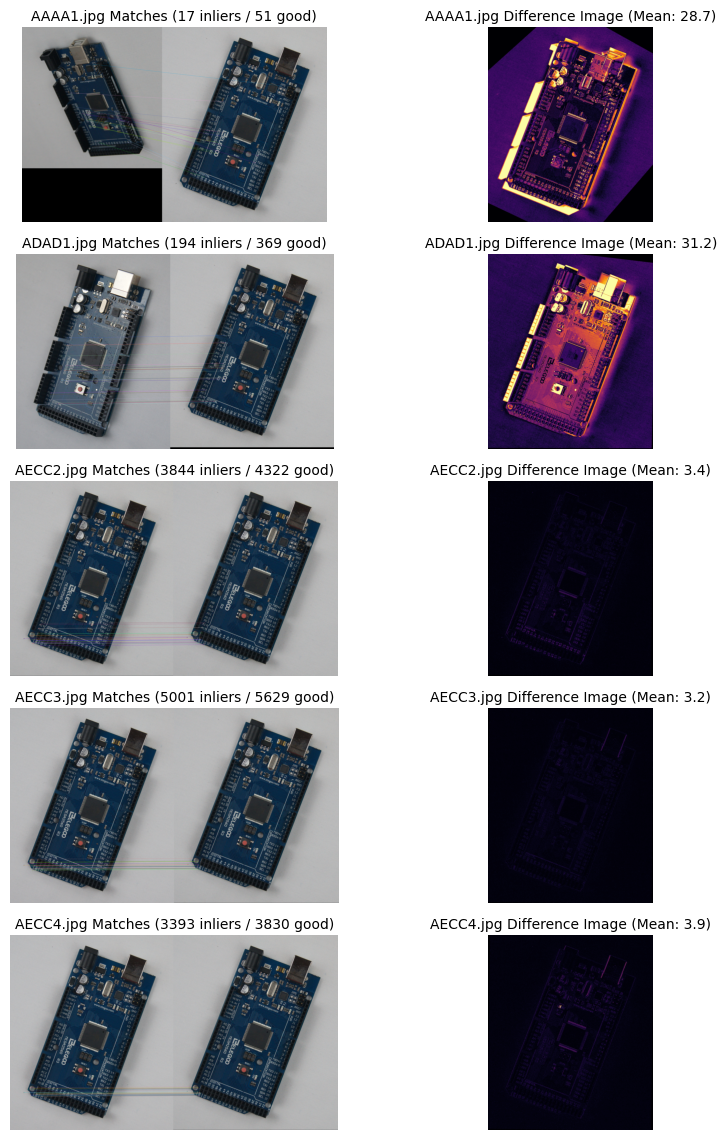

In [5]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

pcb_dir = 'src/pcbs'
template_bgr = cv2.imread(os.path.join(pcb_dir, 'AECC1.jpg'))
template_gray = cv2.cvtColor(template_bgr, cv2.COLOR_BGR2GRAY)
h_t, w_t = template_gray.shape

sift = cv2.SIFT_create()
kp_t, des_t = sift.detectAndCompute(template_gray, None)

targets = ['AAAA1.jpg', 'ADAD1.jpg', 'AECC2.jpg', 'AECC3.jpg', 'AECC4.jpg']
results = {}

for name in targets:
    target_bgr = cv2.imread(os.path.join(pcb_dir, name))
    target_gray = cv2.cvtColor(target_bgr, cv2.COLOR_BGR2GRAY)
    
    kp_tgt, des_tgt = sift.detectAndCompute(target_gray, None)
    
    bf = cv2.BFMatcher()
    matches = bf.knnMatch(des_tgt, des_t, k=2)
    good = [m for m, n in matches if m.distance < 0.75 * n.distance]
    
    src_pts = np.float32([kp_tgt[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp_t[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    
    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
    inliers = [good[idx] for idx, val in enumerate(mask.ravel()) if val == 1]
    
    warped_bgr = cv2.warpPerspective(target_bgr, H, (w_t, h_t))
    diff_bgr = cv2.absdiff(template_bgr, warped_bgr)
    diff_gray = cv2.cvtColor(diff_bgr, cv2.COLOR_BGR2GRAY)
    
    mask_ov = cv2.warpPerspective(np.ones_like(target_gray) * 255, H, (w_t, h_t)) > 200
    mean_val = float(np.mean(diff_gray[mask_ov]))
    
    results[name] = {
        'kp_target': kp_tgt,
        'good': good,
        'inliers': inliers,
        'diff_gray': diff_gray,
        'mask_ov': mask_ov,
        'mean_diff': mean_val
    }

print(f"{'Image':<12}{'Keypoints':<12}{'Good Matches':<14}{'RANSAC Inliers':<16}{'Inlier %':<12}{'Mean Diff':<10}")
print("-" * 76)
for name in targets:
    r = results[name]
    pct = (len(r['inliers']) / len(r['good'])) * 100 if r['good'] else 0
    print(f"{name:<12}{len(r['kp_target']):<12}{len(r['good']):<14}{len(r['inliers']):<16}{pct:<12.1f}{r['mean_diff']:<10.2f}")

# Display feature matches 
fig, axes = plt.subplots(len(targets), 2, figsize=(9.5, 11.5))

for i, name in enumerate(targets):
    r = results[name]
    target_bgr = cv2.imread(os.path.join(pcb_dir, name))
    
    match_vis = cv2.drawMatches(target_bgr, r['kp_target'], template_bgr, kp_t, 
                                r['inliers'][:30], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    
    axes[i, 0].imshow(cv2.cvtColor(match_vis, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"{name} Matches ({len(r['inliers'])} inliers / {len(r['good'])} good)", fontsize=10, pad=4)
    axes[i, 0].axis('off')
    
    disp_diff = r['diff_gray'].copy()
    disp_diff[~r['mask_ov']] = 0
    im = axes[i, 1].imshow(disp_diff, cmap='inferno', vmin=0, vmax=120)
    axes[i, 1].set_title(f"{name} Difference Image (Mean: {r['mean_diff']:.1f})", fontsize=10, pad=4)
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

\noindent\textbf{4.2 Observations}

\vspace{0.1cm}
\begin{itemize}
    \item \textbf{(e) Why 3D elements show high difference:} In images like \texttt{ADAD1} and \texttt{AAAA1}, elements such as the USB port, capacitors, reset button and female headers show high difference values. This happens because a planar homography assumes all points lie on a flat 2D plane. However, these components have physical height ($Z > 0$) rising above the board. When the camera angle or board orientation changes, parallax causes their tops and sides to project to different positions than what a 2D planar transform predicts. Moreover, changing view angles alters shadows and causes  different reflections on the metallic USB casing.
    \item \textbf{Board Alignments:} The boards \texttt{AECC2}, \texttt{AECC3}, and \texttt{AECC4} are identical models in identical orientation, giving over $3300$ inliers and very low mean differences ($\sim 3.2\text{--}3.9$). \texttt{AAAA1} and \texttt{ADAD1} have different orientations although the board layout is the same, resulting in higher difference values ($\sim 28.7\text{--}31.2$).
\end{itemize}